In [1]:
import numpy as np
import pandas as pd
from scipy.stats import norm

In [2]:
forecast_mean = 21.362328
forecast_std = 5.174925227010631

In [3]:
lead_times = [3,5,7,10]
service_levels = [0.90,0.95,0.99]

In [4]:
results = []

for lt in lead_times:
    for sl in service_levels:

        z = norm.ppf(sl)

        safety_stock = z * forecast_std * np.sqrt(lt)

        reorder_point = forecast_mean * lt + safety_stock

        results.append({
            "Lead_Time": lt,
            "Service_Level": sl,
            "Safety_Stock": round(safety_stock,2),
            "Reorder_Point": round(reorder_point,2)
        })

simulation_table = pd.DataFrame(results)

simulation_table

,Lead_Time,Service_Level,Safety_Stock,Reorder_Point
0,3,0.90,11.49,75.57
1,3,0.95,14.74,78.83
2,3,0.99,20.85,84.94
3,5,0.90,14.83,121.64
4,5,0.95,19.03,125.85
5,5,0.99,26.92,133.73
6,7,0.90,17.55,167.08
7,7,0.95,22.52,172.06
8,7,0.99,31.85,181.39
9,10,0.90,20.97,234.60


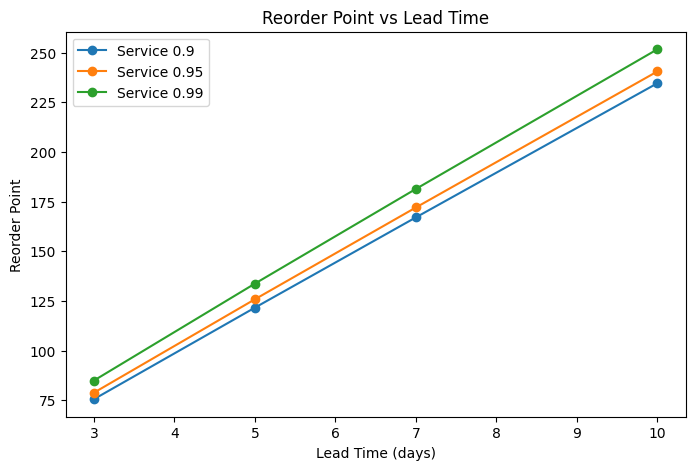

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

for sl in service_levels:
    subset = simulation_table[simulation_table["Service_Level"]==sl]
    plt.plot(subset["Lead_Time"], subset["Reorder_Point"], marker='o', label=f"Service {sl}")

plt.xlabel("Lead Time (days)")
plt.ylabel("Reorder Point")
plt.title("Reorder Point vs Lead Time")
plt.legend()
plt.show()